# Actividad Fundamental 6: Aprendizaje supervisado, arbol de decisión.

**Integrantes del equipo:**

* Angel Yahel Medina Herrera – 2102879
* Mario Alberto Tovanche Casillas – 2024432
* Jose Israel Bautista Rivera – 2127857
* Carlos Segura Cedillo – 2044463
* Humberto Jasso Valadez – 2070160

**Día y hora de clase:** Jueves – N1

## 1. Cargar librerías

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

## 2. Cargar datos

In [39]:
cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target

print('Dimensiones del dataset:', df.shape)
print('Clases:', list(cancer.target_names))
df.head()

Dimensiones del dataset: (569, 31)
Clases: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [40]:
# Distribución de clases (0 = malignant, 1 = benign)
df['target'].value_counts().rename(index={0: 'malignant', 1: 'benign'})

,count
target,
benign,357
malignant,212


## 3. Preprocesamiento de datos

In [41]:
# Revisión de valores nulos
print('Valores nulos totales:', df.isnull().sum().sum())

# Separación de características (X) y etiquetas (y)
X = cancer.data
y = cancer.target

# División 80% entrenamiento / 20% prueba
train_data, test_data, train_labels, test_labels = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Entrenamiento:', train_data.shape, train_labels.shape)
print('Prueba:       ', test_data.shape, test_labels.shape)

Valores nulos totales: 0
Entrenamiento: (455, 30) (455,)
Prueba:        (114, 30) (114,)


> Nota: los árboles de decisión no requieren escalamiento de variables, ya que cada división compara una sola característica contra un umbral.

## 4. Selección y entrenamiento del modelo

In [42]:
model = DecisionTreeClassifier(random_state=42)
model.fit(train_data, train_labels)

print('Profundidad del árbol:', model.get_depth())
print('Número de hojas:', model.get_n_leaves())

Profundidad del árbol: 7
Número de hojas: 19


## 5. Prueba del modelo

In [43]:
# Predicciones con el conjunto de prueba
predictions = model.predict(test_data)
predictions[:20]

array([0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1])

### Matriz de confusión

[[39  3]
 [ 7 65]]


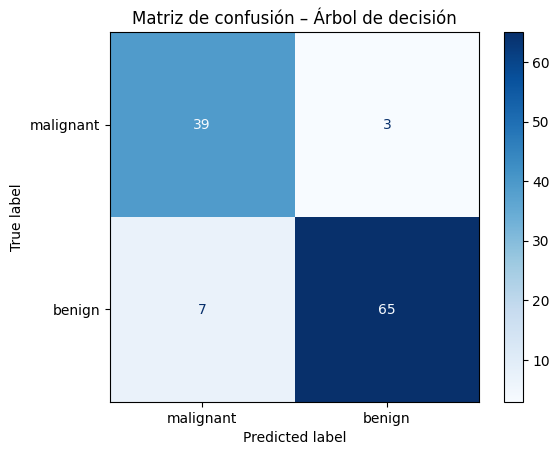

In [44]:
cm = confusion_matrix(test_labels, predictions)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
disp.plot(cmap='Blues')
plt.title('Matriz de confusión – Árbol de decisión')
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

### Precisión (accuracy) y reporte de clasificación

In [45]:
accuracy = accuracy_score(test_labels, predictions)
print(f'Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)\n')

print(classification_report(test_labels, predictions, target_names=cancer.target_names))

Accuracy: 0.9123 (91.23%)

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



### Representación gráfica del árbol de decisión (DPI = 300)

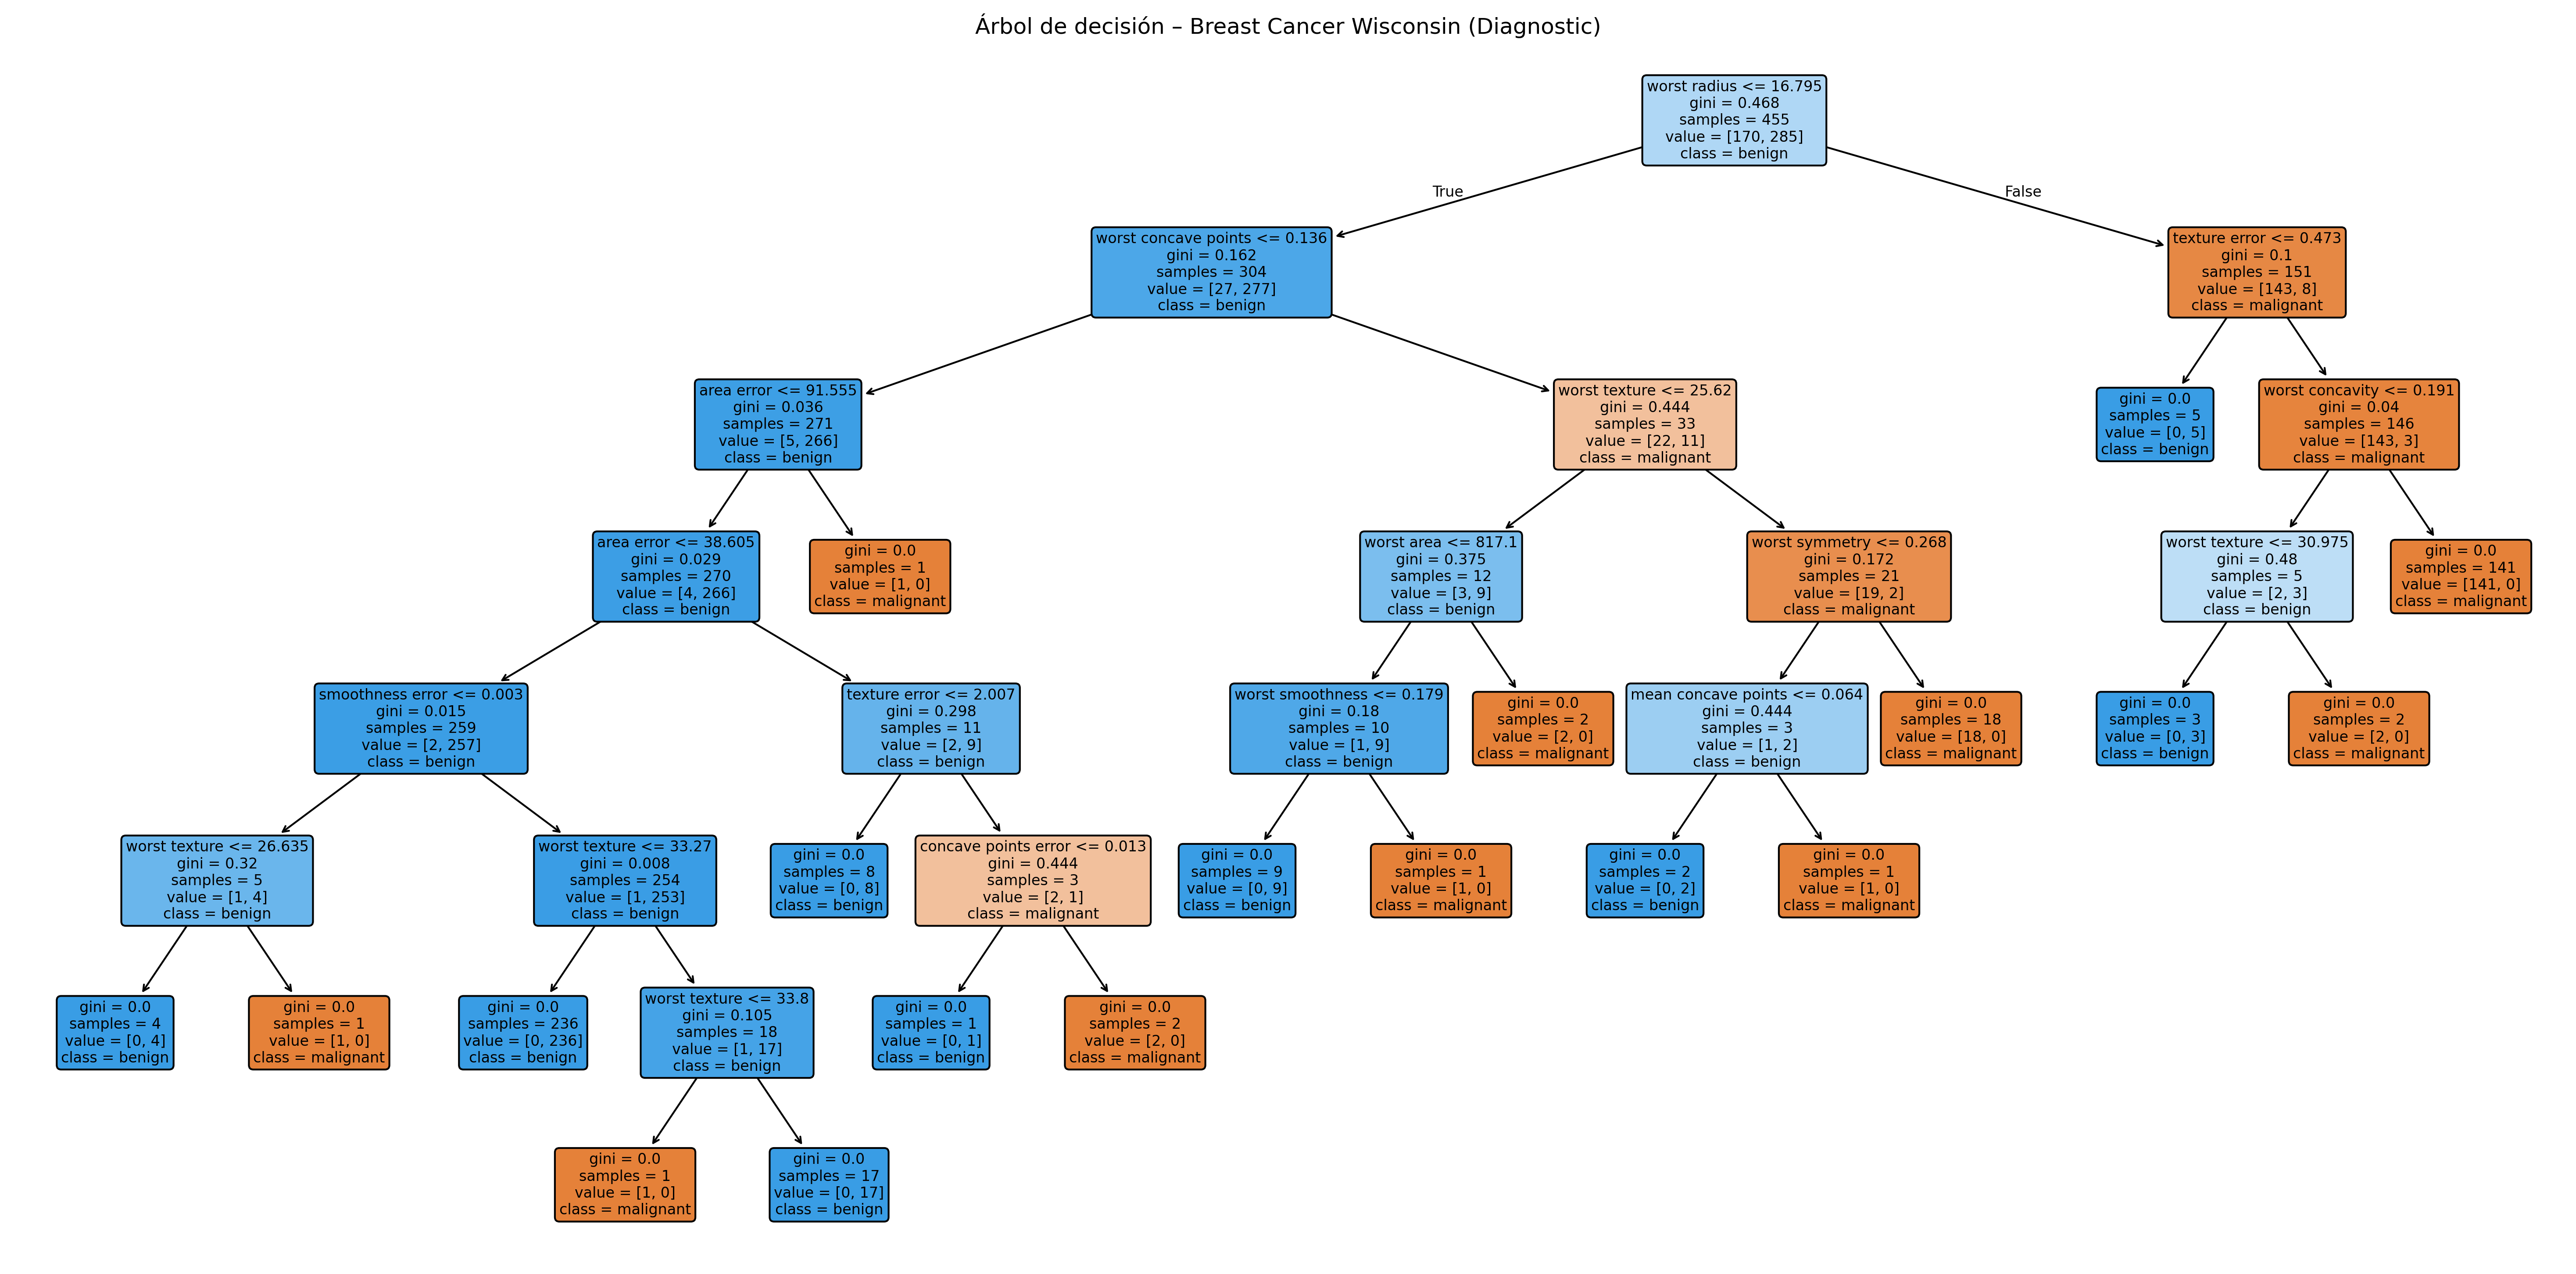

In [46]:
plt.figure(figsize=(25, 12), dpi=300)
plot_tree(
    model,
    feature_names=cancer.feature_names,
    class_names=cancer.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title('Árbol de decisión – Breast Cancer Wisconsin (Diagnostic)')
plt.savefig('decision_tree.png', dpi=300, bbox_inches='tight')
plt.show()